# Lab 1 — Reconstruct a Synthetic Patient’s Data Journey
**AI in Healthcare · B.Tech AI, third year · 120 minutes**

Companion: `session-06-data-ecosystem.md`.

You will inspect healthcare records, define row meanings, audit quality, link tables, construct a cohort, parse FHIR JSON, and visualize time. Prerequisites: basic Python and tables; pandas examples are provided.

All records are invented. They are teaching examples, not clinical evidence or a representative population. This lab trains no model and requires no downloads, credentials, or real patient data.

**How to work:** Run cells in order. Complete each **Student response** and exercise cell. Reference answers are at the end. Submit this notebook with outputs and your interpretations. The generated files go to `healthcare_ecosystem_lab_data/`; rerunning the generator recreates only its named teaching files.

**Schedule:** setup/inventory 15 min; quality/dictionary 20; linkage 25; cohort 20; FHIR 20; plots 15; reflection 5.


> **Submission note:** all exercise cells and *Student response* cells below are completed. Run top-to-bottom in a fresh kernel; every output shown was produced by this notebook. The "Optional reference answers" section is the instructor-provided check cell, left unchanged; it passes against my results.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = Path("healthcare_ecosystem_lab_data")
DATA.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 20)
print("Teaching files:", DATA.resolve())

Teaching files: /Users/pranitsingh/Downloads/Healthcare_Labs/healthcare_ecosystem_lab_data


If imports fail, install `pandas` and `matplotlib` in your notebook environment (for example, `%pip install pandas matplotlib` in a separate cell), then rerun. No package installation is performed automatically.

In [2]:
patients = pd.DataFrame([
    ("P001", 1980), ("P002", 1992), ("P003", 1975), ("P004", 2000)
], columns=["patient_id", "birth_year"])
encounters = pd.DataFrame([
    ("E001", "P001", "2026-01-10T09:00:00+05:30", "outpatient"),
    ("E002", "P001", "2026-02-10T10:00:00+05:30", "outpatient"),
    ("E003", "P002", "2026-01-15T11:00:00+05:30", "outpatient"),
    ("E004", "P003", "2026-01-20T09:00:00+05:30", "outpatient"),
    ("E005", "P003", "2026-03-01T09:00:00+05:30", "outpatient"),
    ("E006", "P004", "2025-12-20T09:00:00+05:30", "outpatient")
], columns=["encounter_id", "patient_id", "start", "type"])
observations = pd.DataFrame([
    ("O001", "E001", "heart_rate", 78, "beats/min", "2026-01-10T09:10:00+05:30"),
    ("O001", "E001", "heart_rate", 78, "beats/min", "2026-01-10T09:10:00+05:30"),
    ("O002", "E001", "temperature", 37, "Cel", "2026-01-10T09:12:00+05:30"),
    ("O003", "E002", "heart_rate", None, "beats/min", "2026-02-10T10:10:00+05:30"),
    ("O004", "E003", "temperature", 98.6, "[degF]", "2026-01-15T11:10:00+05:30"),
    ("O005", "E004", "heart_rate", 84, "beats/min", "2026-01-20T09:10:00+05:30"),
    ("O006", "E005", "heart_rate", 80, "beats/min", "2026-03-01T09:10:00+05:30")
], columns=["observation_id", "encounter_id", "code", "value", "unit", "effective_time"])
notes = pd.DataFrame([
    ("N001", "P001", "E001", "No history of diabetes. Patient reports reduced activity."),
    ("N002", "P001", "E002", "Follow-up visit. Further assessment planned."),
    ("N003", "P002", "E003", "Family history of diabetes; patient history not established.")
], columns=["note_id", "patient_id", "encounter_id", "text"])
times = pd.date_range("2026-01-10T00:00:00+05:30", periods=24, freq="h")
wearable = pd.DataFrame({"patient_id": "P001", "time": times,
                         "steps": [0,0,0,0,0,20,100,250,300,150,80,120,
                                   200,180,90,140,220,400,350,200,100,40,10,0]})
# Deliberately omit six expected hourly samples. A gap is not a zero.
wearable = wearable.drop(index=range(12,18)).reset_index(drop=True)
for name, frame in {"patients":patients, "encounters":encounters,
                    "observations":observations, "notes":notes, "wearable":wearable}.items():
    frame.to_csv(DATA / f"{name}.csv", index=False)

# Small R4-style collection Bundle, separate from the intentionally messy CSV.
# Educational examples; no formal FHIR/profile validator is run here.
resources = [{"resourceType":"Patient", "id":p} for p in patients.patient_id]
for row in encounters.itertuples():
    resources.append({"resourceType":"Encounter", "id":row.encounter_id,
        "status":"finished", "class":{"system":"http://terminology.hl7.org/CodeSystem/v3-ActCode",
        "code":"AMB"}, "subject":{"reference":f"Patient/{row.patient_id}"},
        "period":{"start":row.start}})
for oid, pid, eid, value, time in [
    ("O001","P001","E001",78,"2026-01-10T09:10:00+05:30"),
    ("O005","P003","E004",84,"2026-01-20T09:10:00+05:30")]:
    resources.append({"resourceType":"Observation", "id":oid, "status":"final",
        "code":{"coding":[{"system":"http://loinc.org", "code":"8867-4", "display":"Heart rate"}]},
        "subject":{"reference":f"Patient/{pid}"},
        "encounter":{"reference":f"Encounter/{eid}"}, "effectiveDateTime":time,
        "valueQuantity":{"value":value, "unit":"beats/minute",
        "system":"http://unitsofmeasure.org", "code":"/min"}})
bundle = {"resourceType":"Bundle", "type":"collection", "entry":[
    {"fullUrl":f"https://example.org/fhir/{r['resourceType']}/{r['id']}", "resource":r}
    for r in resources]}
(DATA / "patient_bundle.json").write_text(json.dumps(bundle, indent=2), encoding="utf-8")
print("Created five CSV files and one JSON file.")

Created five CSV files and one JSON file.


## 1. Inventory (0–15 minutes)
Load the generated files as if another team had supplied them. Identify the meaning of one row in each table. Are these sources, representations, or both?


In [3]:
tables = {name: pd.read_csv(DATA / f"{name}.csv")
          for name in ["patients", "encounters", "observations", "notes", "wearable"]}

for name, frame in tables.items():
    print(name, frame.shape)
    display(frame.head(3))
    
patients, encounters, observations, notes, wearable = [tables[n] for n in tables]
encounters["start"] = pd.to_datetime(encounters["start"], utc=True)
observations["effective_time"] = pd.to_datetime(observations["effective_time"], utc=True)
wearable["time"] = pd.to_datetime(wearable["time"], utc=True)

patients (4, 2)


,patient_id,birth_year
0,P001,1980
1,P002,1992
2,P003,1975


encounters (6, 4)


,encounter_id,patient_id,start,type
0,E001,P001,2026-01-10T09:00:00+05:30,outpatient
1,E002,P001,2026-02-10T10:00:00+05:30,outpatient
2,E003,P002,2026-01-15T11:00:00+05:30,outpatient


observations (7, 6)


,observation_id,encounter_id,code,value,unit,effective_time
0,O001,E001,heart_rate,78.0,beats/min,2026-01-10T09:10:00+05:30
1,O001,E001,heart_rate,78.0,beats/min,2026-01-10T09:10:00+05:30
2,O002,E001,temperature,37.0,Cel,2026-01-10T09:12:00+05:30


notes (3, 4)


,note_id,patient_id,encounter_id,text
0,N001,P001,E001,No history of diabetes. Patient reports reduce...
1,N002,P001,E002,Follow-up visit. Further assessment planned.
2,N003,P002,E003,Family history of diabetes; patient history no...


wearable (18, 3)


,patient_id,time,steps
0,P001,2026-01-10 00:00:00+05:30,0
1,P001,2026-01-10 01:00:00+05:30,0
2,P001,2026-01-10 02:00:00+05:30,0


**Student response:** For each file, state its row meaning, identifier(s), representation, and a potential use. Explain why the notes CSV still contains unstructured text. Which lecture sources are not represented here?

**Answer — inventory**

| File | One row means | Identifier(s) | Representation | Potential use |
|---|---|---|---|---|
| `patients.csv` | one synthetic person | `patient_id` (primary key) | structured EHR-style demographic table | denominators, age at visit, linking all other tables |
| `encounters.csv` | one visit/contact with the health system | `encounter_id` (PK), `patient_id` (foreign key) | structured EHR encounter table with ISO-8601 timestamps carrying a +05:30 offset | counting visits, defining cohorts, ordering a patient's timeline |
| `observations.csv` | one recorded measurement (as exported — one row is an accidental duplicate) | `observation_id` (PK, but repeated once), `encounter_id` (FK) | structured long ("tall") table: code + value + unit + time | vital-sign trends, model features (after unit harmonisation) |
| `notes.csv` | one clinical note | `note_id` (PK), `patient_id` and `encounter_id` (FKs) | a table **wrapping** unstructured free text | context, negation, history, plans that are not coded anywhere else |
| `wearable.csv` | one hourly step count for P001 | `patient_id` + `time` (composite key) | patient-generated time series | daily activity patterns between visits |
| `patient_bundle.json` | one FHIR R4 collection Bundle; each `entry` is one resource | `resourceType/id` and `reference` strings | standards-based interchange format (FHIR) | exchanging the same facts between systems |

They are **both**: each file stands in for a *source* (the EHR, a clinician's notes, a wearable device), but what we actually hold is a *representation* — an export whose columns, units and formats were chosen by whoever produced it. The FHIR Bundle is a second representation of a subset of the same facts.

The notes CSV is still unstructured: putting text into a cell gives it a row and keys, but the clinical meaning ("**No** history of diabetes", "**Family** history … patient history **not established**") lives in sentences, not in coded columns. Turning it into structure needs NLP or manual abstraction.

Sources from the lecture that are **not** represented: claims/billing data, medical imaging (DICOM/PACS), physiological waveforms (ECG/EEG), registries, and laboratory results (there is no lab table here).

## 2. Data dictionary and quality audit (15–35 minutes)
Create a dictionary for at least eight columns across three files: meaning, type, unit (if applicable), key role, and missingness interpretation.

Inspect exact duplicate rows, repeated observation IDs, missing values, and measurement units. Do not fill missing measurements with zero.


In [4]:
print("Exact duplicate observation rows:", observations.duplicated().sum())
print("Repeated observation IDs:", observations.observation_id.duplicated().sum())
display(observations.isna().sum().rename("missing_count").to_frame())
display(observations.groupby(["code", "unit"]).size().rename("rows").reset_index())
display(notes.assign(keyword_diabetes=notes.text.str.contains("diabetes", case=False)))

Exact duplicate observation rows: 1
Repeated observation IDs: 1


,missing_count
observation_id,0
encounter_id,0
code,0
value,1
unit,0
effective_time,0


,code,unit,rows
0,heart_rate,beats/min,5
1,temperature,Cel,1
2,temperature,[degF],1


,note_id,patient_id,encounter_id,text,keyword_diabetes
0,N001,P001,E001,No history of diabetes. Patient reports reduce...,True
1,N002,P001,E002,Follow-up visit. Further assessment planned.,False
2,N003,P002,E003,Family history of diabetes; patient history no...,True


In [5]:
# Exercise: data dictionary (15 rows across all five files)
dd_rows = [
    # file, column, meaning, type, unit, key_role, missing_meaning
    ("patients", "patient_id", "Synthetic person identifier", "string", "-", "primary key", "Must never be missing; a missing ID breaks linkage"),
    ("patients", "birth_year", "Year of birth (only year kept, coarser than a full date)", "integer", "year", "attribute", "Unknown/not recorded - not imputable from other tables"),
    ("encounters", "encounter_id", "Visit identifier", "string", "-", "primary key", "Must never be missing"),
    ("encounters", "patient_id", "Person who had the visit", "string", "-", "foreign key -> patients", "Unlinkable visit; investigate rather than drop silently"),
    ("encounters", "start", "Visit start time (ISO-8601, +05:30 offset)", "datetime (tz-aware)", "-", "attribute / cohort filter", "Visit cannot be placed in time; cannot be used in a time-window cohort"),
    ("encounters", "type", "Encounter class (all 'outpatient' here)", "category", "-", "attribute", "Class not recorded; do not assume outpatient"),
    ("observations", "observation_id", "Measurement identifier", "string", "-", "primary key (repeated once in export)", "Must never be missing"),
    ("observations", "encounter_id", "Visit during which the measurement was recorded", "string", "-", "foreign key -> encounters", "Measurement cannot be tied to a visit/patient"),
    ("observations", "code", "What was measured (local code, e.g. heart_rate)", "category", "-", "attribute (needs mapping to LOINC)", "Value is uninterpretable without it"),
    ("observations", "value", "Numeric result", "float", "given by `unit` column", "measurement", "Recorded but no value (e.g. O003) - NOT zero, NOT normal"),
    ("observations", "unit", "Unit of `value` (UCUM-like: beats/min, Cel, [degF])", "category", "per row", "attribute", "Value cannot be compared or converted"),
    ("observations", "effective_time", "Clinically relevant time of the measurement", "datetime (tz-aware)", "-", "attribute", "Cannot order events; availability time is also unknown"),
    ("notes", "text", "Free-text clinical narrative", "string (unstructured)", "-", "content", "No note written - absence of a note is not absence of a condition"),
    ("wearable", "time", "Start of the hourly sampling interval", "datetime (tz-aware)", "-", "part of composite key (patient_id, time)", "An absent hour = no sample supplied (gap), not 0 steps"),
    ("wearable", "steps", "Steps counted in that hour", "integer", "steps/hour", "measurement", "Device off/not worn/not synced - unknown activity"),
]
data_dictionary = pd.DataFrame(dd_rows, columns=["file", "column", "meaning", "type", "unit", "key_role", "missing_meaning"])
# Check the dictionary really describes columns that exist
for f, col in data_dictionary[["file", "column"]].itertuples(index=False):
    assert col in tables[f].columns, (f, col)
print(f"Dictionary covers {len(data_dictionary)} columns across {data_dictionary.file.nunique()} files")
display(data_dictionary)

# Exercise: temperature rows -> value_celsius in a COPY (raw value/unit preserved)
to_celsius = {"Cel": lambda v: v, "[degF]": lambda v: (v - 32) * 5 / 9}
temps = observations.loc[observations["code"] == "temperature"].copy()
unknown_units = set(temps["unit"]) - set(to_celsius)
assert not unknown_units, f"No conversion rule for: {unknown_units}"
temps["value_celsius"] = [round(to_celsius[u](v), 2) for u, v in zip(temps["unit"], temps["value"])]
display(temps[["observation_id", "encounter_id", "value", "unit", "value_celsius"]])
assert observations.loc[observations.code == "temperature", "value"].tolist() == [37, 98.6]  # original untouched


Dictionary covers 15 columns across 5 files


,file,column,meaning,type,unit,key_role,missing_meaning
0,patients,patient_id,Synthetic person identifier,string,-,primary key,Must never be missing; a missing ID breaks lin...
1,patients,birth_year,"Year of birth (only year kept, coarser than a ...",integer,year,attribute,Unknown/not recorded - not imputable from othe...
2,encounters,encounter_id,Visit identifier,string,-,primary key,Must never be missing
3,encounters,patient_id,Person who had the visit,string,-,foreign key -> patients,Unlinkable visit; investigate rather than drop...
4,encounters,start,"Visit start time (ISO-8601, +05:30 offset)",datetime (tz-aware),-,attribute / cohort filter,Visit cannot be placed in time; cannot be used...
5,encounters,type,Encounter class (all 'outpatient' here),category,-,attribute,Class not recorded; do not assume outpatient
6,observations,observation_id,Measurement identifier,string,-,primary key (repeated once in export),Must never be missing
7,observations,encounter_id,Visit during which the measurement was recorded,string,-,foreign key -> encounters,Measurement cannot be tied to a visit/patient
8,observations,code,"What was measured (local code, e.g. heart_rate)",category,-,attribute (needs mapping to LOINC),Value is uninterpretable without it
9,observations,value,Numeric result,float,given by `unit` column,measurement,"Recorded but no value (e.g. O003) - NOT zero, ..."


,observation_id,encounter_id,value,unit,value_celsius
2,O002,E001,37.0,Cel,37.0
4,O004,E003,98.6,[degF],37.0


**Student response:** Identify four quality/interpretation issues. Why is keyword matching unreliable for these notes? What evidence would justify removing a repeated observation ID?

**Answer — quality issues**

1. **Exact duplicate export row:** `O001` appears twice with identical content — an export/ETL artefact that would double-count P001's heart rate.
2. **Missing value:** `O003` (heart rate, E002) has a record, unit and time but no value. It means "not recorded/not available", not 0 bpm and not "normal".
3. **Mixed units for one code:** temperature is `37 Cel` for E001 but `98.6 [degF]` for E003. Comparing raw numbers would suggest a 60-degree fever; after conversion both are 37 °C.
4. **Local, non-standard codes:** `heart_rate`/`temperature` are local strings; they must be mapped (e.g. to LOINC 8867-4) before combining with other sources.
5. **Wearable gap:** six expected hourly samples (12:00–17:00) are absent — a missing period, not zero steps.
6. **Narrative text with negation and attribution:** see below.

**Why keyword matching fails:** `"diabetes"` matches N001 ("**No** history of diabetes" — negated) and N003 ("**Family** history of diabetes; patient history **not established**" — about a relative, and uncertain). The keyword flag is True for both, yet *neither* note says the patient has diabetes. Keyword search ignores negation, experiencer (patient vs family), uncertainty and temporality.

**When is removing a repeated observation ID justified?** Only when the evidence shows it is the *same* event recorded twice: every field is identical (value, unit, encounter, effective time), ideally confirmed by source metadata (export logs, audit trail, last-updated time). A repeated ID with *different* values may be a correction/amendment and needs investigation (keep the latest final version, per the source system's rules). Two different IDs with the same value are two legitimate measurements and must not be removed.

The generator intentionally duplicates one identical export row. We remove exact duplicates for the guided analysis. In real data, a repeated ID with conflicting values requires investigation; a repeated value alone does not justify deletion.


In [6]:
clean_obs = observations.drop_duplicates().copy()
assert clean_obs.observation_id.is_unique
assert patients.patient_id.is_unique
assert encounters.encounter_id.is_unique
print("Raw rows:", len(observations), "After exact deduplication:", len(clean_obs))

Raw rows: 7 After exact deduplication: 6


## 3. Link records without changing their meaning (35–60 minutes)
First attach each encounter to a patient, then attach each observation to its encounter. `validate="many_to_one"` checks that the right-hand keys are unique. The merge indicator checks whether references matched; cardinality validation alone does not check that.


In [7]:
encounter_patient = encounters.merge(patients, on="patient_id", how="left",
                                      validate="many_to_one", indicator=True)
assert encounter_patient["_merge"].eq("both").all()
encounter_patient = encounter_patient.drop(columns="_merge")
linked = clean_obs.merge(encounter_patient, on="encounter_id", how="left",
                         validate="many_to_one", indicator=True)
assert linked["_merge"].eq("both").all()
assert len(linked) == len(clean_obs)
linked = linked.drop(columns="_merge")
display(linked)
print("Rows:", len(linked), "Distinct patients:", linked.patient_id.nunique())

,observation_id,encounter_id,code,value,unit,effective_time,patient_id,start,type,birth_year
0,O001,E001,heart_rate,78.0,beats/min,2026-01-10 03:40:00+00:00,P001,2026-01-10 03:30:00+00:00,outpatient,1980
1,O002,E001,temperature,37.0,Cel,2026-01-10 03:42:00+00:00,P001,2026-01-10 03:30:00+00:00,outpatient,1980
2,O003,E002,heart_rate,NaN,beats/min,2026-02-10 04:40:00+00:00,P001,2026-02-10 04:30:00+00:00,outpatient,1980
3,O004,E003,temperature,98.6,[degF],2026-01-15 05:40:00+00:00,P002,2026-01-15 05:30:00+00:00,outpatient,1992
4,O005,E004,heart_rate,84.0,beats/min,2026-01-20 03:40:00+00:00,P003,2026-01-20 03:30:00+00:00,outpatient,1975
5,O006,E005,heart_rate,80.0,beats/min,2026-03-01 03:40:00+00:00,P003,2026-03-01 03:30:00+00:00,outpatient,1975


Rows: 6 Distinct patients: 3


In [8]:
# Demonstrate multiplication by linking independent encounter and note rows only by patient.
bad_join = encounters.merge(notes[["patient_id", "note_id"]], on="patient_id", how="left")
display(bad_join.loc[bad_join.patient_id.eq("P001"), ["patient_id", "encounter_id", "note_id"]])
# Exercise: join notes to encounters using encounter_id, with appropriate validation.
# Compare P001's row count with the demonstration above.

# --- My solution: link notes to the encounter they were written in ---
notes_by_visit = encounters.merge(
    notes[["encounter_id", "note_id", "patient_id", "text"]],
    on="encounter_id", how="left", suffixes=("", "_note"),
    validate="one_to_many",   # one encounter may legitimately have several notes
    indicator=True)
# A note's own patient_id must agree with its encounter's patient_id
has_note = notes_by_visit["_merge"].eq("both")
assert notes_by_visit.loc[has_note, "patient_id"].eq(notes_by_visit.loc[has_note, "patient_id_note"]).all()
# Every note found its encounter (no orphan notes)
assert notes["encounter_id"].isin(encounters["encounter_id"]).all()
notes_by_visit = notes_by_visit.drop(columns=["patient_id_note", "_merge"])
display(notes_by_visit[["patient_id", "encounter_id", "note_id", "text"]])

p1_bad = bad_join.patient_id.eq("P001").sum()
p1_good = notes_by_visit.patient_id.eq("P001").sum()
print(f"P001 rows -> patient-only join: {p1_bad}, encounter-level join: {p1_good}")
assert (p1_bad, p1_good) == (4, 2)


,patient_id,encounter_id,note_id
0,P001,E001,N001
1,P001,E001,N002
2,P001,E002,N001
3,P001,E002,N002


,patient_id,encounter_id,note_id,text
0,P001,E001,N001,No history of diabetes. Patient reports reduce...
1,P001,E002,N002,Follow-up visit. Further assessment planned.
2,P002,E003,N003,Family history of diabetes; patient history no...
3,P003,E004,NaN,NaN
4,P003,E005,NaN,NaN
5,P004,E006,NaN,NaN


P001 rows -> patient-only join: 4, encounter-level join: 2


**Student response:** What does one row of `linked` represent? Why are four distinct patients in the patient table but fewer in `linked`? How would you retain patients without observations? Explain why the demonstration join misassigns notes.

**Answer — linkage**

- **One row of `linked` = one de-duplicated observation**, enriched with its encounter and patient attributes (6 rows). It is *not* one patient and *not* one visit.
- `linked` contains only **3** patients because it starts from observations: P004 has an encounter (E006) but no observations, so a left join *from observations* never reaches P004.
- To keep everyone, start from the `patients` table and left-join encounters then observations (`patients → encounters → observations`, all `how="left"`). P004 then appears with empty observation columns — and the row grain becomes "patient × encounter × observation (or none)", which has to be documented.
- The demonstration join pairs on `patient_id` only. P001 has 2 encounters and 2 notes, so every encounter is matched to every note: 2 × 2 = **4 rows**, two of which say a note was written during a visit when it was not (e.g. the follow-up note N002 attached to the first visit E001). Joining on `encounter_id` keeps each note with its own visit (2 rows for P001).

## 4. Define a reproducible cohort (60–80 minutes)
**Rule:** Include patients with at least two distinct encounters starting in the half-open interval **[1 January 2026, 1 March 2026)**, measured in Asia/Kolkata local time. Count encounters, not observations. The end boundary is excluded.

Implement the rule in the next cell. Then report included IDs and explain boundary handling. This is a record-availability cohort, not a disease cohort.


In [9]:
window_start = pd.Timestamp("2026-01-01", tz="Asia/Kolkata").tz_convert("UTC")
window_end = pd.Timestamp("2026-03-01", tz="Asia/Kolkata").tz_convert("UTC")
# TODO: filter encounters by start, count distinct encounter_id per patient,
# then retain counts >= 2. Name the resulting DataFrame cohort.

in_window = encounters["start"].ge(window_start) & encounters["start"].lt(window_end)   # [start, end)
visit_counts = (encounters.loc[in_window]
                .groupby("patient_id")["encounter_id"].nunique()
                .rename("encounters_in_window"))

# Show every patient (including those with 0 eligible visits) so exclusions are auditable
audit = (patients[["patient_id"]]
         .merge(visit_counts.reset_index(), on="patient_id", how="left")
         .fillna({"encounters_in_window": 0})
         .astype({"encounters_in_window": int}))
audit["included"] = audit["encounters_in_window"] >= 2
display(audit)

cohort = audit.loc[audit["included"], ["patient_id", "encounters_in_window"]].reset_index(drop=True)
print("Cohort:", cohort.patient_id.tolist())

# Boundary check: which visits fall on/after the excluded end boundary?
local = encounters.assign(start_local=encounters.start.dt.tz_convert("Asia/Kolkata"), in_window=in_window)
display(local[["patient_id", "encounter_id", "start_local", "in_window"]])
assert cohort.patient_id.tolist() == ["P001"]


,patient_id,encounters_in_window,included
0,P001,2,True
1,P002,1,False
2,P003,1,False
3,P004,0,False


Cohort: ['P001']


,patient_id,encounter_id,start_local,in_window
0,P001,E001,2026-01-10 09:00:00+05:30,True
1,P001,E002,2026-02-10 10:00:00+05:30,True
2,P002,E003,2026-01-15 11:00:00+05:30,True
3,P003,E004,2026-01-20 09:00:00+05:30,True
4,P003,E005,2026-03-01 09:00:00+05:30,False
5,P004,E006,2025-12-20 09:00:00+05:30,False


**Student response:** State your cohort result and why P003 is excluded. Would counting rows after an observations join give a reliable visit count? Why does this selection not prove anything about disease risk?

**Answer — cohort**

- **Cohort = {P001}** (2 distinct encounters: 10 Jan and 10 Feb 2026).
- **P003 is excluded** because its second visit (E005) starts at **2026-03-01 09:00 IST**, which is on/after the excluded end boundary of the half-open window [1 Jan, 1 Mar). Only E004 counts, so P003 has 1 eligible visit. P002 has one visit; P004's only visit (20 Dec 2025) is before the window.
- Boundaries were built in Asia/Kolkata local time and converted to UTC, and timestamps were parsed as UTC, so comparisons are between the same instants — no off-by-5.5-hours error. Using `>=` start and `<` end implements the half-open interval exactly.
- **Counting rows after joining observations is not a reliable visit count:** each encounter is multiplied by its number of observations (E001 has 2 → would count as 2 visits) and encounters with zero observations disappear (E006). That is why I count `nunique()` of `encounter_id` on the encounter table.
- **This proves nothing about disease risk:** it selects patients with *records available* (≥2 visits), which reflects access to care, follow-up scheduling and data capture. There is no diagnosis, outcome or comparison group, and the 4 patients are invented.

## 5. Read FHIR JSON (80–100 minutes)
The collection Bundle packages Patient, Encounter, and Observation resources. The extraction below handles only the simple reference and quantity pattern in this fixture. Production FHIR supports additional reference forms, value types, optional fields, and profiles.

FHIR R4 references: [Observation](https://hl7.org/fhir/R4/observation.html), [Bundle](https://hl7.org/fhir/R4/bundle.html). Successful JSON parsing is not formal FHIR validation.


In [10]:
bundle_loaded = json.loads((DATA / "patient_bundle.json").read_text(encoding="utf-8"))
resource_index = {f"{e['resource']['resourceType']}/{e['resource']['id']}": e["resource"]
                  for e in bundle_loaded["entry"]}
fhir_rows = []
for resource in resource_index.values():
    if resource["resourceType"] != "Observation":
        continue
    patient_ref = resource["subject"]["reference"]
    encounter_ref = resource["encounter"]["reference"]
    assert patient_ref in resource_index and encounter_ref in resource_index
    assert resource_index[encounter_ref]["subject"]["reference"] == patient_ref
    coding = next(c for c in resource["code"]["coding"] if c["system"] == "http://loinc.org")
    q = resource["valueQuantity"]
    fhir_rows.append({"observation_id":resource["id"],
        "patient_id":patient_ref.split("/")[-1], "encounter_id":encounter_ref.split("/")[-1],
        "loinc_code":coding["code"], "value":q["value"], "ucum_code":q["code"],
        "effective_time":resource["effectiveDateTime"]})
fhir_frame = pd.DataFrame(fhir_rows)
fhir_frame["effective_time"] = pd.to_datetime(fhir_frame["effective_time"], utc=True)
display(fhir_frame)

,observation_id,patient_id,encounter_id,loinc_code,value,ucum_code,effective_time
0,O001,P001,E001,8867-4,78,/min,2026-01-10 03:40:00+00:00
1,O005,P003,E004,8867-4,84,/min,2026-01-20 03:40:00+00:00


In [11]:
# Explicit mappings apply only to the codes/units in this teaching fixture.
comparison_source = linked.copy()
comparison_source["loinc_code"] = comparison_source.code.map({"heart_rate":"8867-4"})
comparison_source["ucum_code"] = comparison_source.unit.map({"beats/min":"/min"})
comparison = fhir_frame.merge(comparison_source, on="observation_id", how="left",
                              suffixes=("_fhir", "_csv"), validate="one_to_one", indicator=True)
assert comparison["_merge"].eq("both").all()
for field in ["patient_id", "encounter_id", "loinc_code", "value", "ucum_code", "effective_time"]:
    assert comparison[f"{field}_fhir"].eq(comparison[f"{field}_csv"]).all(), field
print("All two FHIR observations agree with their CSV counterparts on identity, code, value, unit, and time.")

All two FHIR observations agree with their CSV counterparts on identity, code, value, unit, and time.


**Student response:** Locate the subject reference, encounter reference, coding system, and quantity in the JSON file. Why did we compare coded units instead of display labels? Why are there fewer FHIR observations than CSV observations? Does this comparison establish completeness or clinical validity?

**Answer — FHIR**

In `patient_bundle.json`, inside each `entry[i].resource` whose `resourceType` is `"Observation"`:

- subject reference → `"subject": {"reference": "Patient/P001"}`
- encounter reference → `"encounter": {"reference": "Encounter/E001"}`
- coding system → `"code": {"coding": [{"system": "http://loinc.org", "code": "8867-4", "display": "Heart rate"}]}`
- quantity → `"valueQuantity": {"value": 78, "unit": "beats/minute", "system": "http://unitsofmeasure.org", "code": "/min"}`

**Why coded units?** The display label is free text for humans: the CSV says `beats/min`, the FHIR `unit` says `beats/minute` — they differ as strings but mean the same thing. The UCUM `code` (`/min`) under a declared `system` is the machine-comparable value, so we map the CSV unit to UCUM and compare codes.

**Why fewer FHIR observations?** The generator deliberately put only 2 heart-rate observations (O001, O005) in the Bundle; the CSV has 6 (after dedup), including temperatures and the missing-value O003. The Bundle is a subset/extract, not a mirror.

**Does the comparison establish completeness or clinical validity?** No. It shows the two shared records *agree* on identity, code, value, unit and time. It says nothing about the 4 records missing from FHIR (completeness), and agreement between two copies does not show the original measurement was correct (validity). Both could carry the same upstream error. JSON parsing also is not formal FHIR profile validation.

## 6. Visualize a journey and missing samples (100–115 minutes)
We know from the synthetic generator that one sample per hour was expected. In real data, verify the expected sampling schedule before calling absent timestamps “missing.” Times below are shown in Asia/Kolkata.


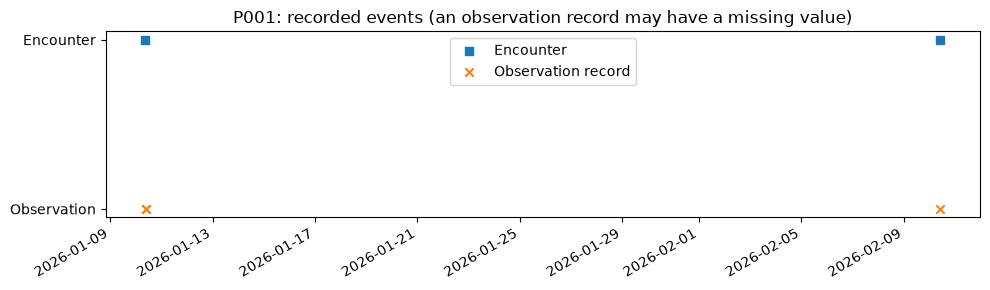

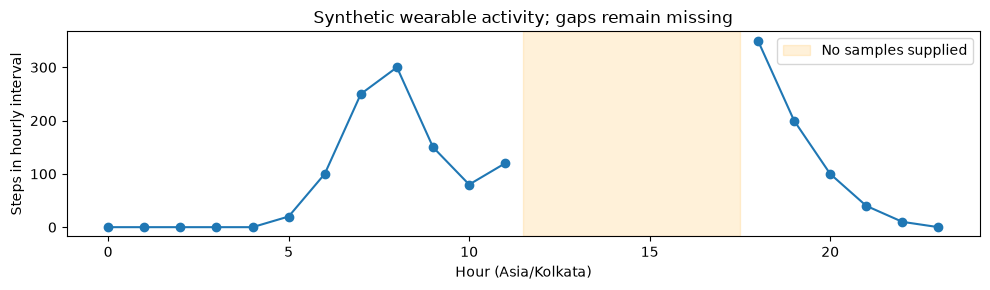

Missing expected hourly samples: 6


In [12]:
p1_encounters = encounters.loc[encounters.patient_id.eq("P001")]
p1_obs = linked.loc[linked.patient_id.eq("P001")]
fig, ax = plt.subplots(figsize=(10, 3))
ax.scatter(p1_encounters.start.dt.tz_convert("Asia/Kolkata"), [1]*len(p1_encounters), label="Encounter", marker="s")
ax.scatter(p1_obs.effective_time.dt.tz_convert("Asia/Kolkata"), [0]*len(p1_obs), label="Observation record", marker="x")
ax.set_yticks([0, 1], ["Observation", "Encounter"])
ax.set_title("P001: recorded events (an observation record may have a missing value)")
ax.legend(loc="upper center")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

expected = pd.date_range("2026-01-10", periods=24, freq="h", tz="Asia/Kolkata")
series = wearable.set_index("time")["steps"].tz_convert("Asia/Kolkata").reindex(expected)
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(series.index.hour, series.values, marker="o")
ax.axvspan(11.5, 17.5, alpha=0.15, color="orange", label="No samples supplied")
ax.set(xlabel="Hour (Asia/Kolkata)", ylabel="Steps in hourly interval", title="Synthetic wearable activity; gaps remain missing")
ax.legend()
plt.tight_layout()
plt.show()
print("Missing expected hourly samples:", series.isna().sum())

**Student response:** Explain the orange region. What false conclusion might result from replacing these missing samples with zero? Why does the timeline include O003 even though its numeric value is missing?

**Answer — visualisation**

- **The orange region** marks hours 12–17 (local) for which the wearable supplied **no sample**. The plotted line breaks there because the values are `NaN`, not 0.
- **Replacing with zero** would show the patient as completely inactive from noon to 5 pm: it would lower daily step totals (the true hourly values in that period were 200–400 in the generator), suggest an inactivity episode or illness, and bias any model feature such as "daily steps" or "longest sedentary period". In reality the device may have been charging, removed or unsynced.
- **O003 appears on the timeline** because the observation *event* happened: it has an ID, encounter and `effective_time` — only its numeric value is missing. The timeline plots when records exist, not their values. Dropping it would hide the fact that a measurement was attempted/recorded without a result, which is itself informative for data-quality review.

## 7. Final reflection and submission (115–120 minutes)
Answer in 150–250 words:

1. What information was lost when the FHIR observations were flattened into a table?
2. Which three limitations would matter before training a model on a dataset like this?
3. If predicting at encounter start, would measurements recorded ten minutes later be available? What additional timestamp might be needed in a real system?

**Submit:** executed notebook, completed dictionary, cohort code/result, join exercise, and written responses. Rubric: inventory/dictionary 2; quality interpretation 2; linkage 2; cohort 1; FHIR comparison 1; plots/reflection 2 (10 total).

Synthetic relationships are intentionally simple. Do not use this fixture to evaluate model performance, disease prevalence, or clinical usefulness.

---
## Optional reference answers — consult after attempting the exercises
These cells are executable worked solutions. Your own responses above remain the assessed work.



### Final reflection (my response)

**1. Information lost when flattening FHIR.** The flat table kept only ID, patient, encounter, LOINC code, value, UCUM code and time. It dropped the resource `status` ("final"), the coding `system` URLs and `display` text, the human-readable unit label, the `fullUrl` of each entry, the Bundle type, and the reference structure itself (we split `"Patient/P001"` into a bare string, losing the resource type). Any extra codings, extensions or nested elements would also be lost without warning.

**2. Three limitations before training a model.** (a) *Size and realism:* 4 invented patients, 6 observations — no statistical signal, and the relationships are hand-made. (b) *Data quality and representation:* duplicates, a missing value, mixed units, local codes and an untagged wearable gap would all corrupt features if not handled explicitly; notes need negation- and experiencer-aware NLP, not keywords. (c) *No labels or outcome and no linkage guarantees:* there is no diagnosis or outcome to predict, and the cohort reflects record availability, so any model would learn care-access patterns rather than disease.

**3. Prediction at encounter start.** No — a heart rate with `effective_time` 10 minutes after the visit start does not exist yet at encounter start; using it would be **temporal leakage**. A real system also needs the **availability/recorded time** (when the value was entered or became queryable, e.g. FHIR `issued` or an audit/`lastUpdated` timestamp), because event time and availability time can differ by minutes to days (lab results, late-documented notes).


In [13]:
temperature_answer = clean_obs.loc[clean_obs.code.eq("temperature")].copy()
assert temperature_answer.unit.isin(["Cel", "[degF]"]).all()
temperature_answer["value_celsius"] = temperature_answer.apply(
    lambda r: (r.value - 32) * 5 / 9 if r.unit == "[degF]" else r.value, axis=1)
display(temperature_answer)

correct_notes_answer = encounters.merge(notes[["encounter_id", "note_id", "text"]],
                                        on="encounter_id", how="left", validate="one_to_many")
assert len(correct_notes_answer.loc[correct_notes_answer.patient_id.eq("P001")]) == 2

eligible_answer = encounters.loc[encounters.start.ge(window_start) & encounters.start.lt(window_end)]
counts_answer = eligible_answer.groupby("patient_id").encounter_id.nunique()
cohort_answer = counts_answer[counts_answer.ge(2)].rename("encounter_count").reset_index()
display(cohort_answer)
assert cohort_answer.patient_id.tolist() == ["P001"]
assert len(clean_obs) == 6
assert linked.patient_id.nunique() == 3
assert series.isna().sum() == 6
print("Reference checks passed.")

,observation_id,encounter_id,code,value,unit,effective_time,value_celsius
2,O002,E001,temperature,37.0,Cel,2026-01-10 03:42:00+00:00,37.0
4,O004,E003,temperature,98.6,[degF],2026-01-15 05:40:00+00:00,37.0


,patient_id,encounter_count
0,P001,2


Reference checks passed.


### Interpretation guide

- Quality issues include one exact duplicate, one missing value, temperature values using different units, and note wording that defeats simple disease keyword flags. The wearable adds a six-sample gap.
- `linked` has one row per deduplicated observation. P004 has an encounter but no observation rows. Start from patients and use left joins if retaining all patients is the goal; document the resulting granularity.
- The patient-only join pairs each of P001's two visits with both notes, producing four rows. Encounter linkage preserves each note's visit. Multiple legitimate notes per encounter could still expand rows.
- P001 has two visits in the cohort interval. P003's second visit is on the excluded March 1 boundary. Count distinct encounters to avoid counting multiple observations as visits.
- FHIR is deliberately a subset with two observations. Agreement on selected fields does not establish completeness. Flattening drops status, full URLs, coding-system details, and other resource context from the original JSON.
- A gap in supplied wearable samples is not evidence of inactivity. O003 is a documented observation row whose value is absent; it still has an event time.
- Event time and availability time can differ. Inputs must have been available at the intended prediction time.
- A useful dictionary describes `patient_id` as a synthetic person key, `encounter_id` as a visit key, `observation_id` as an observation key, `effective_time` as measurement time, and `value` together with `code` and `unit`. Missing meanings must not be invented when the source does not specify them.
